In [2]:
%pip install "tensorflow[cuda]" mlflow pandas azure-storage-blob matplotlib opencv-python scikit-learn


  Using cached mlflow-3.17.2-py3-none-any.whl (12.0 MB)
  Using cached pandas-2.3.3-cp310-cp310-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (12.8 MB)
  Using cached azure_storage_blob-12.31.0-py3-none-any.whl (455 kB)
  Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.8 MB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl (73.8 MB)
  Using cached scikit_learn-1.7.2-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.7 MB)
  Using cached graphene-3.4.3-py2.py3-none-any.whl (114 kB)
  Using cached alembic-1.20.1-py3-none-any.whl (270 kB)
  Using cached sqlalchemy-2.0.55-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (3.4 MB)
  Using cached aiohttp-3.14.5-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (1.9 MB)
  Using cached flask-3.1.3-py3-none-any.whl (103 kB)
  Using cached flask_cors-6.0.5-py3-none-any.whl (16 kB)
  Using cached mlflow_

In [3]:
import os
import sys
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("Num GPUs Available:", len(gpus))
if gpus:
    for gpu in gpus:
        print("  ->", gpu)


2026-10-22 16:37:45.402420: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792687065.420483    1529 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792687065.425907    1529 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792687065.439947    1529 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792687065.439970    1529 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792687065.439971    1529 computation_placer.cc:177] computation placer alr

Num GPUs Available: 1
  -> PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [4]:
import os
from azure.storage.blob import BlobServiceClient

# set AZURE_STORAGE_CONNECTION_STRING in the environment first
service = BlobServiceClient.from_connection_string(os.environ["AZURE_STORAGE_CONNECTION_STRING"])
container = service.get_container_client("kcrowly-vast")


In [5]:
# Download dataset from Azure Blob Storage if not already present locally
import os
import tarfile

data_archive = "neurovision_data.tar.gz"
data_dir = "Data/raw" if os.path.exists("Data/raw") else ("../Data/raw" if os.path.exists("../Data/raw") else "Data/raw")

if not os.path.exists(data_dir):
    print("Data folder not found locally. Downloading from Azure Blob Storage...")
    with open(data_archive, "wb") as f:
        download_stream = container.download_blob("data/neurovision_data.tar.gz")
        f.write(download_stream.readall())
    print("Download complete. Extracting dataset and helpers...")
    with tarfile.open(data_archive, "r:gz") as tar:
        tar.extractall(".")
    data_dir = "Data/raw" if os.path.exists("Data/raw") else "../Data/raw"
    print(f"Dataset ready at: {data_dir}")
else:
    print(f"Dataset already available at: {data_dir}")


Data folder not found locally. Downloading from Azure Blob Storage...
Download complete. Extracting dataset and helpers...
Dataset ready at: Data/raw


Total MRI images: 7023 | Classes: ('glioma', 'meningioma', 'notumor', 'pituitary')


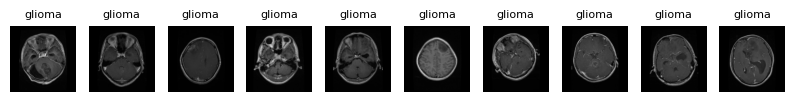

In [6]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Add src to path to import neurovision.data helper functions
sys.path.insert(0, os.path.abspath("src"))
sys.path.insert(0, os.path.abspath("../src"))
sys.path.insert(0, os.path.abspath("."))

from neurovision import data

paths, labels, _ = data.list_image_files(data_dir)
print(f"Total MRI images: {len(paths)} | Classes: {data.CLASSES}")

# Preview sample MRI scans
plt.figure(figsize=(10, 2))
for i in range(min(10, len(paths))):
    plt.subplot(1, 10, i + 1)
    img = cv2.cvtColor(data.load_image(paths[i]), cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    plt.title(data.CLASSES[labels[i]], fontsize=8)
    plt.axis("off")
plt.show()


RestNet50 PreProc

In [7]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

# Create MRI-specific augmentation using data.py helper
augmentation = data.make_augmentation(rotation=0.03, zoom=0.1, translation=0.1, seed=42)

# Build train, validation and test datasets with MobileNetV2 preprocessing ([-1, 1])
datasets = data.make_datasets(
    data_dir,
    size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    val_split=0.15,
    test_split=0.15,
    seed=42,
    augmentation=augmentation,
    preprocess="mobilenet"
)

# Format targets to one-hot encoding for categorical_crossentropy
train_ds = datasets["train"].map(lambda x, y: (x, tf.one_hot(y, data.NUM_CLASSES)),
                                num_parallel_calls=tf.data.AUTOTUNE)
test_ds = datasets["test"].map(lambda x, y: (x, tf.one_hot(y, data.NUM_CLASSES)),
                               num_parallel_calls=tf.data.AUTOTUNE)

print("Datasets successfully prepared with data.py!")


I0000 00:00:1792687090.412434    1529 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22315 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:4a:00.0, compute capability: 8.6


Datasets successfully prepared with data.py!


In [8]:
from tensorflow.keras.applications import VGG16
base_model = VGG16(weights="imagenet",
                        include_top=False,
                        input_shape=(224, 224, 3))
base_model.trainable = False


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step 


In [9]:
from tensorflow.keras import layers, models

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(data.NUM_CLASSES, activation="softmax")  # 4 classes for Brain Tumor
])
model.compile(optimizer="adam",
             loss="categorical_crossentropy",
             metrics=["accuracy"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,868 (56.38 MB)

 Trainable params: 66,180 (258.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
checkpoint = ModelCheckpoint("vgg-16-neurovision.keras", save_best_only=True)

history = model.fit(train_ds, validation_data=test_ds, epochs=10,
                   callbacks=[early_stop, checkpoint])


Epoch 1/10


I0000 00:00:1792687096.656942    1944 service.cc:152] XLA service 0x7759ec00f0d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792687096.656979    1944 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 3090, Compute Capability 8.6
2026-10-22 16:38:16.739806: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792687097.889773    1944 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-10-22 16:38:19.690227: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_921', 188 bytes spill stores, 188 bytes spill loads

2026-10-22 16:38:19.706811: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1413

  5/154 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.2475 - loss: 1.5249 

I0000 00:00:1792687103.735616    1944 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4827 - loss: 1.1896

2026-10-22 16:38:31.043092: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1413', 32 bytes spill stores, 32 bytes spill loads

2026-10-22 16:38:31.072944: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_921', 200 bytes spill stores, 200 bytes spill loads

2026-10-22 16:38:31.100761: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1413', 56 bytes spill stores, 56 bytes spill loads



154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.4835 - loss: 1.1883

2026-10-22 16:38:34.821398: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_234', 4 bytes spill stores, 4 bytes spill loads

2026-10-22 16:38:37.636324: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_227', 200 bytes spill stores, 200 bytes spill loads



154/154 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - accuracy: 0.4843 - loss: 1.1870 - val_accuracy: 0.8178 - val_loss: 0.6221
Epoch 2/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.7616 - loss: 0.6783 - val_accuracy: 0.7941 - val_loss: 0.5271
Epoch 3/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step - accuracy: 0.7875 - loss: 0.5750 - val_accuracy: 0.8501 - val_loss: 0.4459
Epoch 4/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.8126 - loss: 0.5107 - val_accuracy: 0.8577 - val_loss: 0.4073
Epoch 5/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.8355 - loss: 0.4704 - val_accuracy: 0.8577 - val_loss: 0.3954
Epoch 6/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - accuracy: 0.8341 - loss: 0.4445 - val_accuracy: 0.8548 - val_loss: 0.4000
Epoch 7/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.8365 - loss: 0.4329 - val_accuracy: 0.8643 - val_loss: 0.3634
Epoch 8/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step - accuracy: 0.8442 - loss: 0.4284 - val_accuracy: 0.8

In [11]:
with open("vgg-16-neurovision.keras", "rb") as f:
    container.upload_blob("models/vgg-16-neurovision.keras", f, overwrite=True)
print("Uploaded mobilenetv2_neurovision.keras to Azure Blob Storage!")


Uploaded mobilenetv2_neurovision.keras to Azure Blob Storage!


In [12]:
import subprocess, time

subprocess.run(["pkill", "-f", "mlflow"])
time.sleep(3)

p = subprocess.Popen(
    ["mlflow", "server", "--host", "0.0.0.0", "--port", "5000",
     "--disable-security-middleware"],
    stdout=open("mlflow.log", "w"), stderr=subprocess.STDOUT,
)
time.sleep(15)

print("exit code:", p.poll())
print(open("mlflow.log").read()[-1500:])


exit code: None
ild_environ
/venv/main/lib/python3.10/site-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi import WSGIResponder, build_environ
2026/10/22 16:40:06 INFO:     Started server process [4549]
2026/10/22 16:40:06 INFO:     Waiting for application startup.
2026/10/22 16:40:06 INFO:     Application startup complete.
2026/10/22 16:40:06 INFO:     Started server process [4551]
2026/10/22 16:40:06 INFO:     Waiting for application startup.
2026/10/22 16:40:06 INFO:     Application startup complete.
2026/10/22 16:40:06 INFO:     Started server process [4552]
2026/10/22 16:40:06 INFO:     Waiting for application startup.
2026/10/22 16:40:06 INFO:     Application startup complete.
2026/10/22 16:40:06 INFO:     Started server process [4550]
2026/10/22 16:40:06 INFO:     Waiting f

## Fine Tuning

In [13]:
loss, acc = model.evaluate(test_ds)
print(f"Test Accuracy: {acc:.2f}")


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.8925 - loss: 0.3137
Test Accuracy: 0.88


In [18]:
base_model.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,868 (56.38 MB)

 Trainable params: 14,780,868 (56.38 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
fine_tune_epochs = 10
total_epochs = 10 + fine_tune_epochs

history_fine = model.fit(train_ds,
                         epochs=total_epochs,
                         initial_epoch=10,
                         validation_data=test_ds)


Epoch 11/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 52s 215ms/step - accuracy: 0.8533 - loss: 0.3750 - val_accuracy: 0.9118 - val_loss: 0.2471
Epoch 12/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 135ms/step - accuracy: 0.9218 - loss: 0.2329 - val_accuracy: 0.9336 - val_loss: 0.1835
Epoch 13/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 136ms/step - accuracy: 0.9508 - loss: 0.1551 - val_accuracy: 0.9478 - val_loss: 0.1680
Epoch 14/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 137ms/step - accuracy: 0.9736 - loss: 0.0978 - val_accuracy: 0.9137 - val_loss: 0.2880
Epoch 15/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 136ms/step - accuracy: 0.9790 - loss: 0.0734 - val_accuracy: 0.9535 - val_loss: 0.1287
Epoch 16/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 136ms/step - accuracy: 0.9794 - loss: 0.0628 - val_accuracy: 0.9535 - val_loss: 0.1519
Epoch 17/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 137ms/step - accuracy: 0.9814 - loss: 0.0577 - val_accuracy: 0.9602 - val_loss: 0.1388
Epoch 18/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 137ms/step - accuracy: 0.9909 -

## Evaluation :


In [16]:
loss, acc = model.evaluate(test_ds)
print(f"Test Accuracy: {acc:.2f}")


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9637 - loss: 0.1225
Test Accuracy: 0.96


In [17]:
# Save and upload the final fine-tuned model to Azure Blob Storage
finetuned_model_path = "vgg-16_neurovision_finetuned.keras"
model.save(finetuned_model_path)

with open(finetuned_model_path, "rb") as f:
    container.upload_blob(f"models/{finetuned_model_path}", f, overwrite=True)
print(f"Successfully uploaded {finetuned_model_path} to Azure Blob Storage!")


Successfully uploaded vgg-16_neurovision_finetuned.keras to Azure Blob Storage!
